## import file và thư viện

In [ ]:
import sys
import os

sys.path.append(os.path.abspath(".."))
from Ho_tro import Pipeline_of_project as pl
from Ho_tro import bio_utils as bu
from Ho_tro import task_utils as tu
import json
import slot_filling as sl
import json
import time
from collections import Counter
import pickle
import Model_HMM as mh 
import numpy as np
import feature_extractor as fe
import Model_CRF as mc    
import evaluate_diversity as ed
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix


MODEL_CRF_PATH = "./trained_model/crf_model.npz"            
MODEL_HMM_PATH = "./trained_model/hmm_model.pkl"



In [5]:
import importlib
importlib.reload(pl)
importlib.reload(bu)
importlib.reload(fe)
importlib.reload(mc)
importlib.reload(sl)
importlib.reload(tu)
importlib.reload(mh)
importlib.reload(ed)



<module 'evaluate_diversity' from 'd:\\Học\\Môn Học Trên Trường\\NLP\\Project_cuối_kì\\Code\\Model\\evaluate_diversity.py'>

## Lấy data


### Lấy data nè

In [6]:
paths = []
paths.append("..\..\Data\Dữ liệu Huấn Luyện\Train_Test_Dev_Anno4.json")

data_tong_hop, error = pl.pipeline_chuan_bi_data_training(paths)

X_test_2, Y_test_2 = tu.lay_dong(data_tong_hop, "train")

In [7]:
X_test, Y_test, error_train = tu.doc_du_lieu_mo("..\..\Data\Dữ liệu Huấn Luyện\Du_lieu_test.json")


In [8]:
len_a = int(len(X_test_2)/10)
X_test = X_test + X_test_2[:len_a]
Y_test = Y_test + Y_test_2[:len_a]

In [9]:
X_test_pt1, Y_test_pt1, error_train = tu.doc_du_lieu_mo("..\..\Data\Phân tích bắt buộc\Emoji_va_ky_tu_dac_biet.json")
X_test_pt2, Y_test_pt2, error_train = tu.doc_du_lieu_mo("..\..\Data\Phân tích bắt buộc\Teencode_va_sai_chinh_ta.json")



### Phân tích chúttt

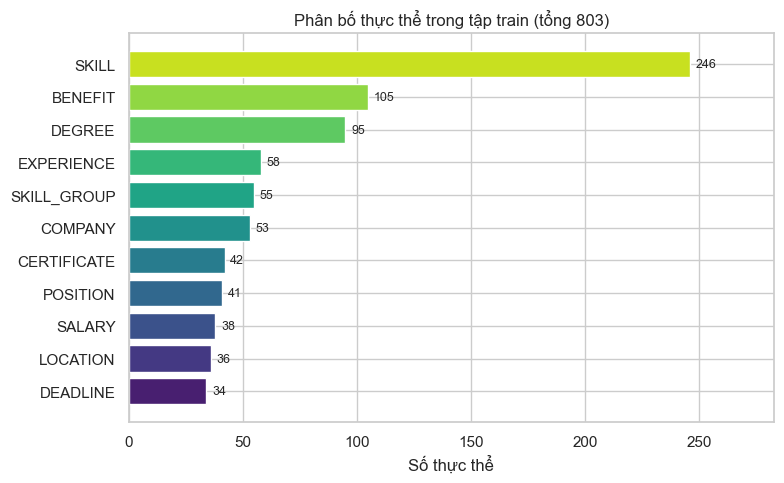

In [10]:

dem_thuc_the = Counter(tag[2:] for dong in Y_test for tag in dong if tag.startswith("B-"))

loai   = list(dem_thuc_the.keys())
so_luong = list(dem_thuc_the.values())

cap = sorted(zip(so_luong, loai))          
so_luong = [x[0] for x in cap]
loai     = [x[1] for x in cap]

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.barh(loai, so_luong,
               color=sns.color_palette("viridis", len(loai)))
for b, sl in zip(bars, so_luong):
    ax.text(b.get_width() + max(so_luong) * 0.01,
            b.get_y() + b.get_height() / 2,
            f"{sl}", va="center", fontsize=9)

ax.set_xlabel("Số thực thể")
ax.set_title(f"Phân bố thực thể trong tập train (tổng {sum(so_luong)})",
             fontsize=12)
ax.set_xlim(0, max(so_luong) * 1.15)       

plt.tight_layout()
plt.show()

## Đánh giá mô hình CRF

### Nạp Mô Hình CRF

In [11]:
crf_test = mc.CRF.nap_mo_hinh(MODEL_CRF_PATH, fe.FeatureExtractor)

In [12]:
Y_pred_CRF = crf_test.predict(X_test)

### Strict-match Entity-level precision, recall và F1 của từng loại thực thể, micro và cả macro 

In [13]:
def ve_bieu_do(kq: dict):
    df = pd.DataFrame(kq["tung_nhan"]).T[["p", "r", "f1"]]
    df.columns = ["Precision", "Recall", "F1"]
    df = df.sort_values("F1", ascending=False)
    
    fig, ax = plt.subplots(figsize=(14, 7), dpi=120)
    
    colors = ["#ef4444", "#3b82f6", "#10b981"]
    
    df.plot(
        kind="bar", 
        ax=ax, 
        color=colors, 
        edgecolor="white", 
        linewidth=1.2, 
        width=0.8, 
        rot=45,
        zorder=3
    )
    
    ax.set_axisbelow(True)
    ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)
    
    # Tăng pad lên một chút để title có khoảng thở
    ax.set_title(f"Đánh giá mô hình NER (Micro F1: {kq['micro']['f1']:.4f})", fontsize=16, fontweight="bold", pad=15)
    ax.set_ylabel("Điểm số", fontsize=12, fontweight="bold")
    ax.set_xlabel("Nhãn", fontsize=12, fontweight="bold")
    ax.set_ylim(0, 1.15)
    
    ax.set_xticklabels(df.index, rotation=45, ha='right', fontsize=11)
    ax.tick_params(axis='y', labelsize=11)
    
    # SỬA Ở ĐÂY: Đưa legend vào góc trên bên phải TRONG biểu đồ
    ax.legend(loc="upper right", frameon=True, fontsize=11)
    
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3, fontsize=8, color='#333333', fontweight='bold')
        
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#cccccc')
    ax.spines['bottom'].set_color('#cccccc')
    
    plt.tight_layout()
    plt.show()

In [30]:


def ve_confusion_matrix_ner(Y_that, Y_doan):
    flat_that = []
    flat_doan = []
    
    for seq_that, seq_doan in zip(Y_that, Y_doan):
        min_len = min(len(seq_that), len(seq_doan))
        flat_that.extend(seq_that[:min_len])
        flat_doan.extend(seq_doan[:min_len])
    
    def clean_tag(tag):
        if tag == "O":
            return "O"
        return tag.split("-")[-1]

    cleaned_that = [clean_tag(t) for t in flat_that]
    cleaned_doan = [clean_tag(t) for t in flat_doan]
    
    all_labels = sorted(list(set(cleaned_that + cleaned_doan) - {"O"}))
    labels = ["O"] + all_labels

    cm = confusion_matrix(cleaned_that, cleaned_doan, labels=labels)

    plt.figure(figsize=(12, 9))
    cm_log = np.log1p(cm) 
    
    sns.heatmap(cm_log, annot=cm, fmt='d', cmap='YlOrRd',
                xticklabels=labels, yticklabels=labels,
                cbar_kws={'label': 'Log(Số lượng)'})
    
    plt.title("Confusion Matrixn", fontsize=14, fontweight='bold')
    plt.xlabel("Nhãn Dự Đoán")
    plt.ylabel("Nhãn Thực Tế")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

In [14]:
kq_crf = bu.danh_gia(Y_test,Y_pred_CRF)

nhãn                 P       R      F1   số thật
BENEFIT          0.818   0.771   0.794       105
CERTIFICATE      1.000   0.976   0.988        42
COMPANY          0.133   0.038   0.059        53
DEADLINE         1.000   1.000   1.000        34
DEGREE           0.686   0.505   0.582        95
EXPERIENCE       0.933   0.700   0.800        60
LOCATION         0.850   0.986   0.913        69
POSITION         0.804   0.902   0.851        41
SALARY           0.923   0.947   0.935        38
SKILL            0.657   0.874   0.750       246
SKILL_GROUP      0.481   0.446   0.463        56
------------------------------------------------
micro            0.742   0.750   0.746       839
macro F1                         0.740


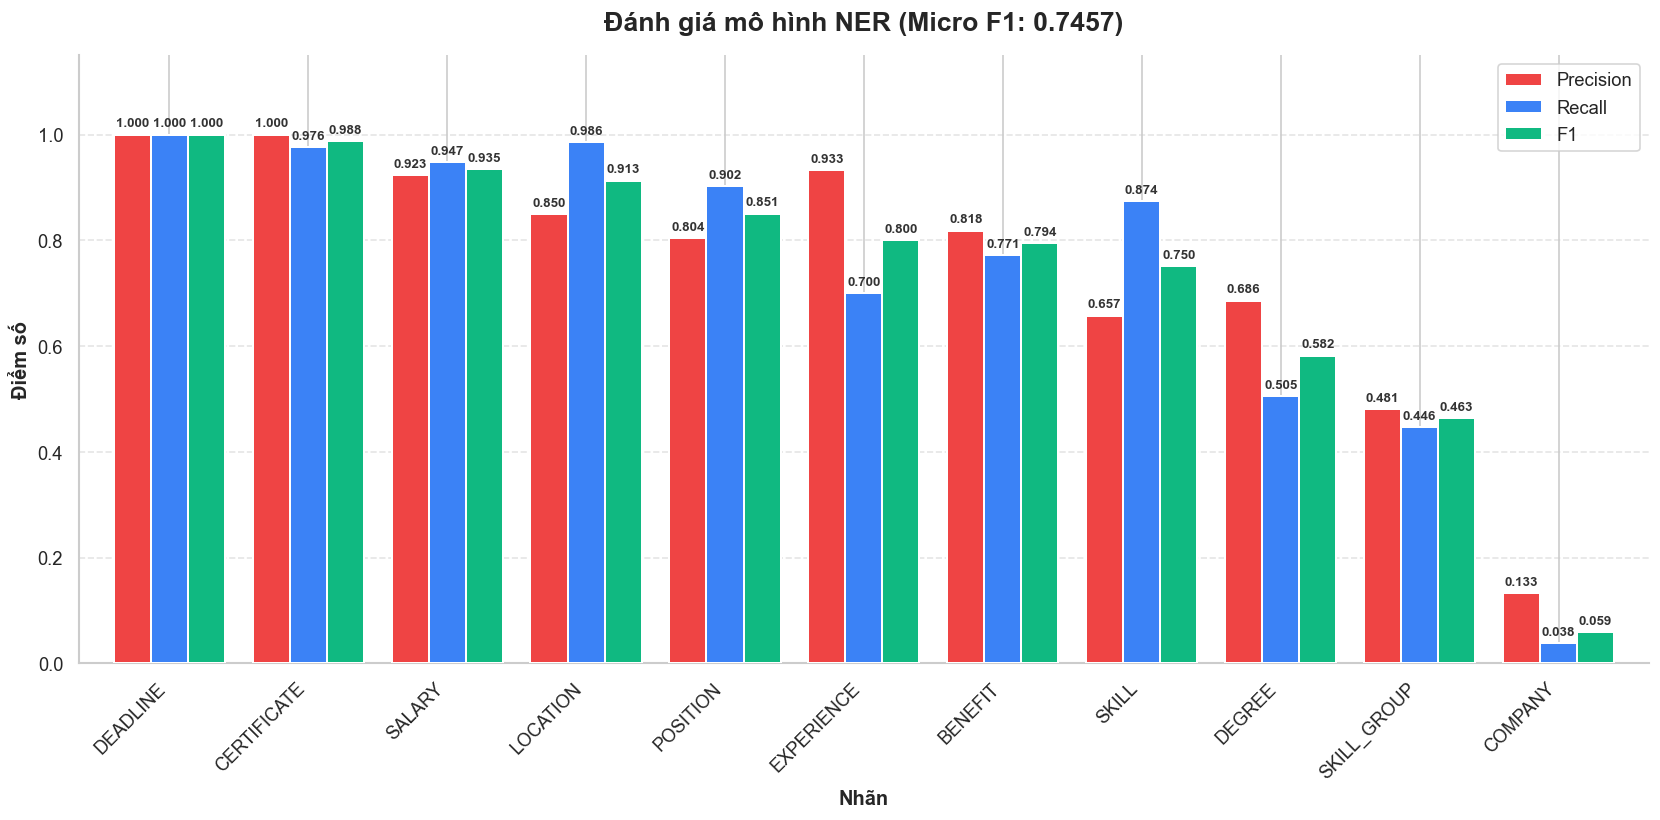

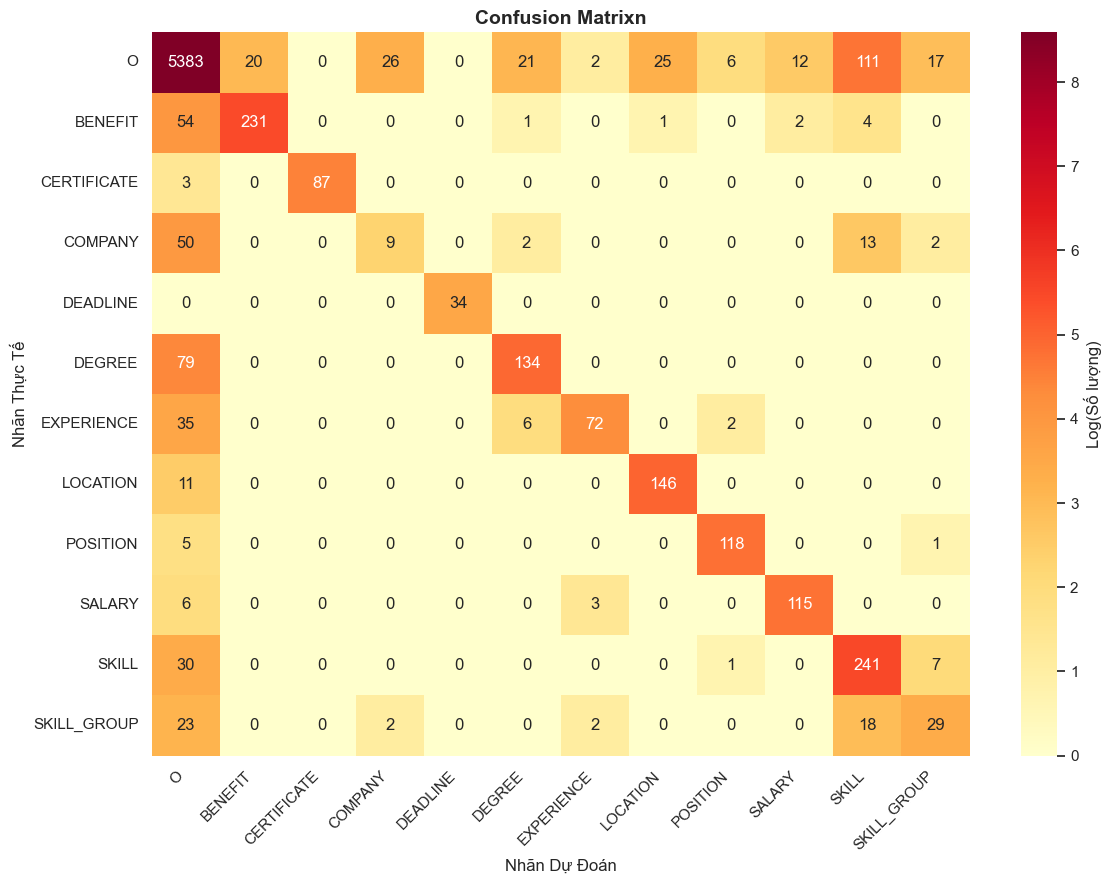

In [31]:
bu.in_ket_qua(kq_crf)
ve_bieu_do(kq_crf)
ve_confusion_matrix_ner(Y_test,Y_pred_CRF)

## Đánh giá mô hình HMM

### Nạp mô hình HMM

In [16]:
with open(MODEL_HMM_PATH, "rb") as f:
    hmm_loaded = pickle.load(f)

print("Nạp mô hình HMM thành công!")


Nạp mô hình HMM thành công!


### Strict-match Entity-level precision, recall và F1 của từng loại thực thể, micro và cả macro 

In [17]:
Y_pred_HMM = hmm_loaded.predict_tu_list_token(X_test)


nhãn                 P       R      F1   số thật
BENEFIT          0.562   0.390   0.461       105
CERTIFICATE      0.250   0.095   0.138        42
COMPANY          0.265   0.566   0.361        53
DEADLINE         0.000   0.000   0.000        34
DEGREE           0.860   0.389   0.536        95
EXPERIENCE       0.588   0.333   0.426        60
LOCATION         0.227   0.145   0.177        69
POSITION         0.484   0.366   0.417        41
SALARY           0.625   0.263   0.370        38
SKILL            0.814   0.732   0.771       246
SKILL_GROUP      0.510   0.464   0.486        56
------------------------------------------------
micro            0.581   0.445   0.504       839
macro F1                         0.377


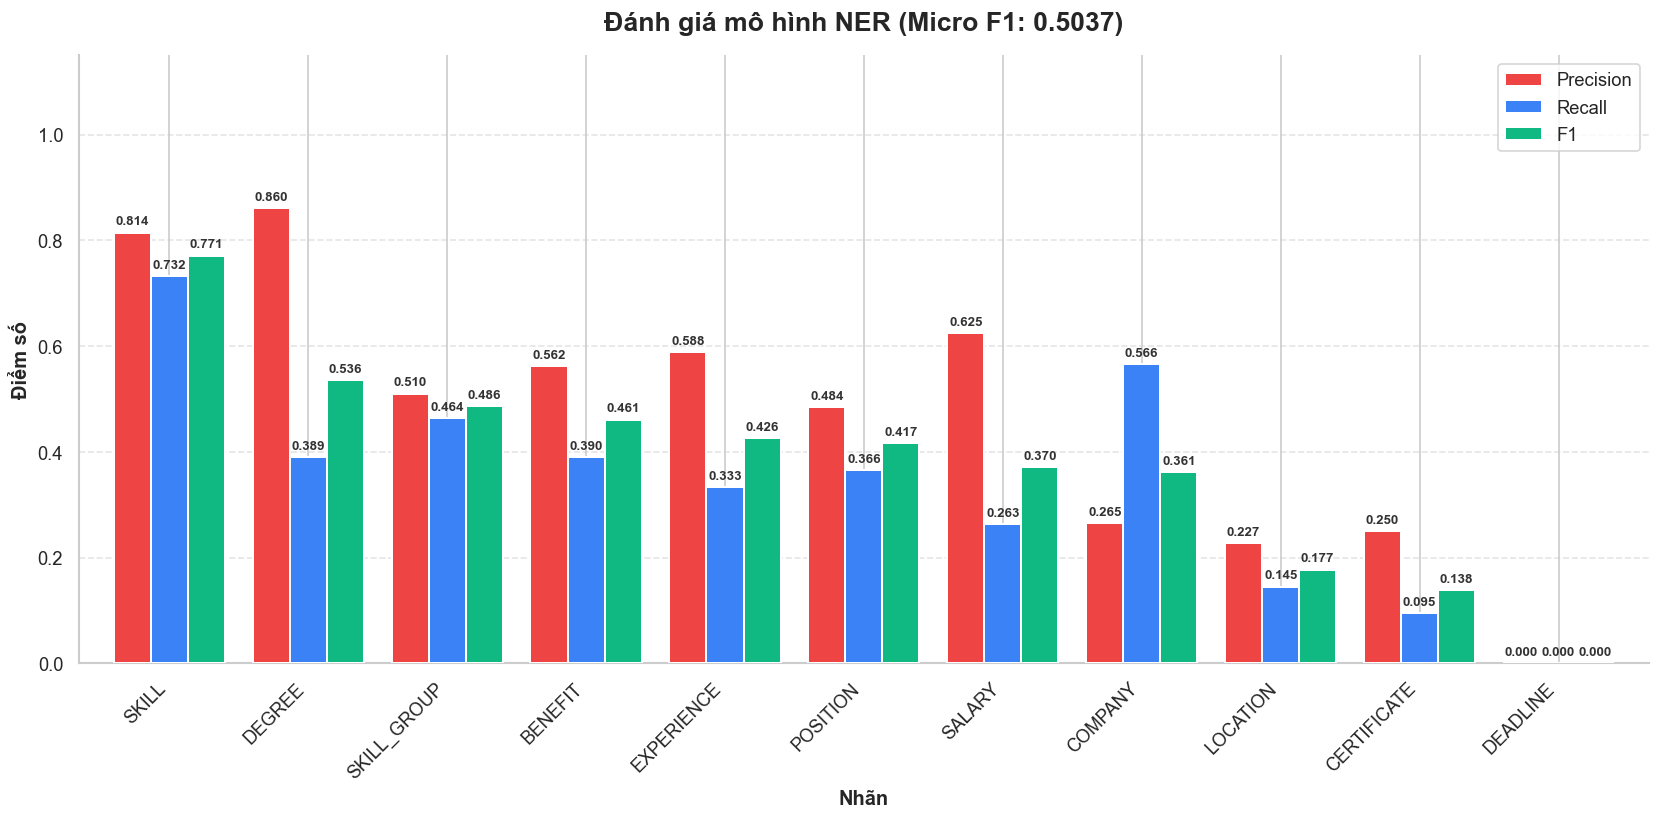

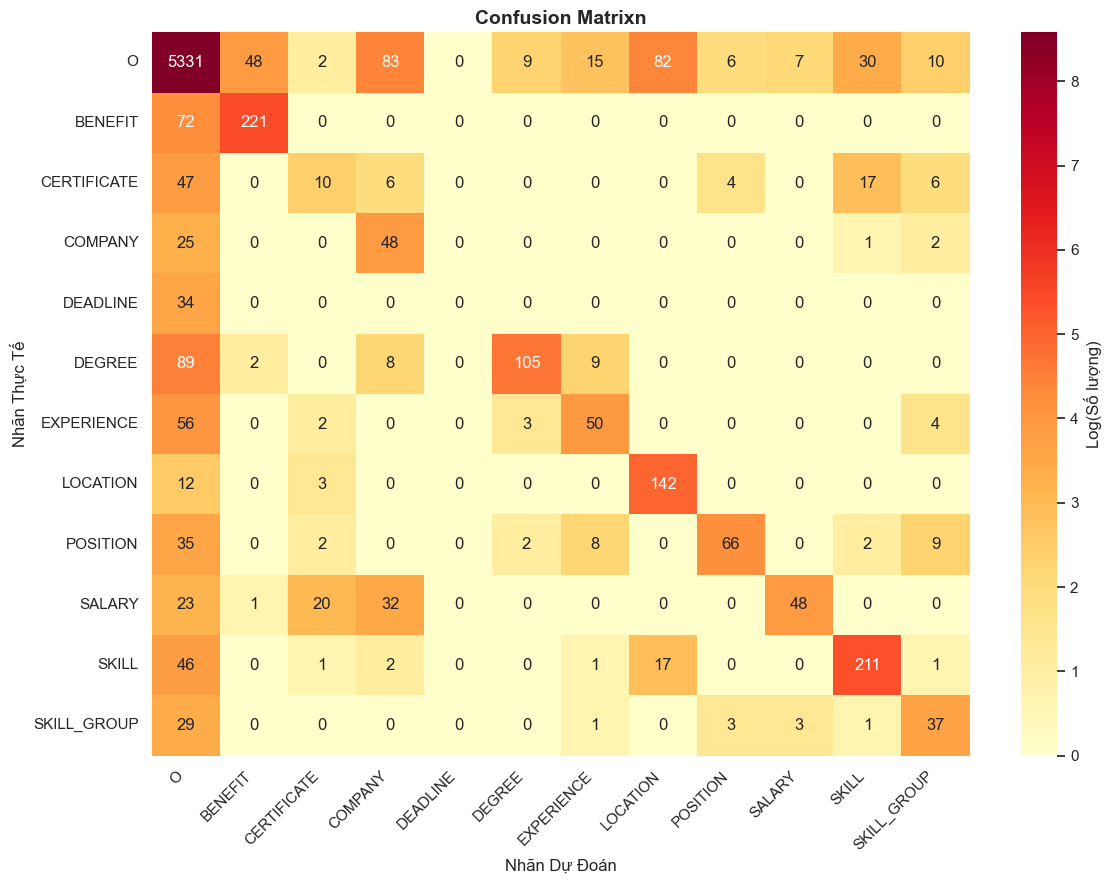

In [32]:
ket_qua_hmm = bu.danh_gia(Y_test, Y_pred_HMM)

bu.in_ket_qua(ket_qua_hmm)
ve_bieu_do(ket_qua_hmm)
ve_confusion_matrix_ner(Y_test, Y_pred_HMM)

## Slot filling

### Accuracy của bước chuẩn hóa

Tạo dữ liệu mẫu

In [19]:
TASK1 = tu.build_task("test_01_basic", [
    ("FPT Software tuyển Senior Python Developer", [
        ("COMPANY",  "FPT Software"),
        ("POSITION", "Senior Python Developer"),
    ]),
    ("Địa điểm: Hồ Chí Minh", [
        ("LOCATION", "Hồ Chí Minh"),
    ]),
    ("Lương: 20-30 triệu VND", [
        ("SALARY", "20-30 triệu VND"),
    ]),
    ("Kinh nghiệm: 2-3 năm backend", [
        ("EXPERIENCE", "2-3 năm"),
        ("EXPERIENCE", "backend"),
    ]),
    ("Yêu cầu: Đại học CNTT", [
        ("DEGREE", "Đại học"),
        ("DEGREE", "CNTT"),
    ]),
    ("Chứng chỉ: IELTS 6.5", [
        ("CERTIFICATE", "IELTS 6.5"),
    ]),
    ("Kỹ năng: Python, Django", [
        ("SKILL", "Python"),
        ("SKILL", "Django"),
    ]),
    ("Hạn nộp: 30/10/2026", [
        ("DEADLINE", "30/10/2026"),
    ]),
    ("Quyền lợi: 12 ngày phép", [
        ("BENEFIT", "12 ngày phép"),
    ]),
])

GOLD1 = {
    "task_id": "test_01",
    "company":   {"raw": "FPT Software", "name": "FPT Software", "source": "ner"},
    "position":  {"raw": "Senior Python Developer", "title": "Senior Python Developer", "source": "ner"},
    "locations": [{"raw": "Hồ Chí Minh", "city": "HCM", "address": "Hồ Chí Minh", "source": "ner"}],
    "salary": {
        "raw": "20-30 triệu VND", "type": "range",
        "min": 20_000_000, "max": 30_000_000,
        "currency": "VND", "period": "month",
    },
    "experience": [{
        "raw": "2-3 năm backend",
        "min_years": 2, "max_years": 3,
        "domains": ["backend"],
        "level": "required", "related_ok": False,
    }],
    "degree": [{
        "degree_raw": "Đại học", "degree_level": "bachelor",
        "majors": ["CNTT"],
        "related_ok": False, "level": "required",
    }],
    "certificates": [{
        "type": "language",
        "detail": [{"name": "IELTS", "grade": "6.5"}],
        "level": "required", "related_ok": False,
    }],
    "skill_groups": [
        {"name": "PROGRAMMING", "level": "required", "source": "kb", "related_ok": False,
         "skills": [{"name": "Python", "raw": "Python", "level": "required", "source": "ner"}]},
        {"name": "BACKEND",     "level": "required", "source": "kb", "related_ok": False,
         "skills": [{"name": "Django", "raw": "Django", "level": "required", "source": "ner"}]},
    ],
    "deadline": {"raw": "30/10/2026", "type": "date", "date": "2026-10-30", "source": "ner"},
    "benefits": [{"raw": "12 ngày phép", "category": "leave"}],
}

In [20]:
TASK2 = tu.build_task("test_02_skills", [
    ("TechCorp tuyển Senior Backend Engineer Python", [
        ("COMPANY",  "TechCorp"),
        ("POSITION", "Senior Backend Engineer Python"),
    ]),
    ("Kinh nghiệm: 3-5 năm backend", [
        ("EXPERIENCE", "3-5 năm"),
        ("EXPERIENCE", "backend"),
    ]),
    ("Kỹ năng: Backend: Node.js, Express", [
        ("SKILL_GROUP", "Backend"),
        ("SKILL", "Node.js"),
        ("SKILL", "Express"),
    ]),
    ("Docker và AWS là lợi thế", [
        ("SKILL", "Docker"),
        ("SKILL", "AWS"),
    ]),
    ("Chứng chỉ: TOEIC 900 hoặc tương đương", [
        ("CERTIFICATE", "TOEIC 900"),
        ("CERTIFICATE", "tương đương"),
    ]),
    ("Yêu cầu: Đại học CNTT hoặc ngành liên quan", [
        ("DEGREE", "Đại học"),
        ("DEGREE", "CNTT"),
    ]),
    ("Lương: cạnh tranh", [
        ("SALARY", "cạnh tranh"),
    ]),
])

GOLD2 = {
    "task_id": "test_02",
    "company":   {"raw": "TechCorp", "name": "TechCorp", "source": "ner"},
    "position":  {"raw": "Senior Backend Engineer Python",
                  "title": "Senior Backend Engineer Python", "source": "ner"},
    "locations": [],
    "salary": {
        "raw": "cạnh tranh", "type": "negotiable",
        "min": None, "max": None,
        "currency": "VND", "period": "month",
    },
    "experience": [{
        "raw": "3-5 năm backend",
        "min_years": 3, "max_years": 5,
        "domains": ["backend"],
        "level": "required", "related_ok": False,
    }],
    "degree": [{
        "degree_raw": "Đại học", "degree_level": "bachelor",
        "majors": ["CNTT"],
        "related_ok": True, "level": "required",
    }],
    "certificates": [{
        "type": "language",
        "detail": [{"name": "TOEIC", "grade": "900"}],
        "level": "required", "related_ok": True,
    }],
    "skill_groups": [
        {"name": "BACKEND",     "level": "required",  "source": "ner", "related_ok": False,
         "skills": [
             {"name": "Node.js",    "raw": "Node.js", "level": "required", "source": "ner"},
             {"name": "Express.js", "raw": "Express", "level": "required", "source": "ner"},
         ]},
        {"name": "DEVOPS",      "level": "preferred", "source": "kb",  "related_ok": False,
         "skills": [{"name": "Docker", "raw": "Docker", "level": "preferred", "source": "ner"}]},
        {"name": "CLOUD",       "level": "preferred", "source": "kb",  "related_ok": False,
         "skills": [{"name": "AWS", "raw": "AWS", "level": "preferred", "source": "ner"}]},
        {"name": "PROGRAMMING", "level": "required",  "source": "kb",  "related_ok": False,
         "skills": [{"name": "Python", "raw": None, "level": "required", "source": "kb"}]},
    ],
    "deadline": {"raw": None, "type": None, "date": None, "source": None},
    "benefits": [],
}

In [21]:
TASK3 = tu.build_task("test_03_edge", [
    ("Startup XYZ tuyển Fullstack Developer", [
        ("COMPANY",  "Startup XYZ"),
        ("POSITION", "Fullstack Developer"),
    ]),
    ("Địa điểm: 123 Lê Lợi, Quận 1, TP.HCM", [
        ("LOCATION", "123 Lê Lợi, Quận 1, TP.HCM"),
    ]),
    ("Lương: Thỏa thuận", [
        ("SALARY", "Thỏa thuận"),
    ]),
    ("Kinh nghiệm: ít nhất 2 năm", [
        ("EXPERIENCE", "ít nhất 2 năm"),
    ]),
    ("Kỹ năng: Backend: Node.js", [
        ("SKILL_GROUP", "Backend"),
        ("SKILL", "Node.js"),
    ]),
    ("Ưu tiên React.js, Vue.js", [
        ("SKILL", "React.js"),
        ("SKILL", "Vue.js"),
    ]),
    ("Chứng chỉ: IELTS 7.0 và TOEIC 950", [
        ("CERTIFICATE", "IELTS 7.0"),
        ("CERTIFICATE", "TOEIC 950"),
    ]),
    ("Bằng cấp: Cao đẳng CNTT", [
        ("DEGREE", "Cao đẳng"),
        ("DEGREE", "CNTT"),
    ]),
    ("Hạn nộp: Khi tuyển đủ", [
        ("DEADLINE", "Khi tuyển đủ"),
    ]),
])

GOLD3 = {
    "task_id": "test_03",
    "company":   {"raw": "Startup XYZ", "name": "Startup XYZ", "source": "ner"},
    "position":  {"raw": "Fullstack Developer", "title": "Fullstack Developer", "source": "ner"},
    "locations": [{
        "raw": "123 Lê Lợi, Quận 1, TP.HCM", "city": "HCM",
        "address": "123 Lê Lợi, Quận 1, TP.HCM", "source": "ner",
    }],
    "salary": {
        "raw": "Thỏa thuận", "type": "negotiable",
        "min": None, "max": None,
        "currency": "VND", "period": "month",
    },
    "experience": [{
        "raw": "ít nhất 2 năm",
        "min_years": 2, "max_years": None,
        "domains": [],
        "level": "required", "related_ok": False,
    }],
    "degree": [{
        "degree_raw": "Cao đẳng", "degree_level": "college",
        "majors": ["CNTT"],
        "related_ok": False, "level": "required",
    }],
    "certificates": [{
        "type": "language",
        "detail": [
            {"name": "IELTS", "grade": "7.0"},
            {"name": "TOEIC", "grade": "950"},
        ],
        "level": "required", "related_ok": False,
    }],
    "skill_groups": [
        {"name": "BACKEND",  "level": "required",  "source": "ner", "related_ok": False,
         "skills": [{"name": "Node.js", "raw": "Node.js", "level": "required", "source": "ner"}]},
        {"name": "FRONTEND", "level": "preferred", "source": "kb",  "related_ok": False,
         "skills": [
             {"name": "React.js", "raw": "React.js", "level": "preferred", "source": "ner"},
             {"name": "Vue.js",   "raw": "Vue.js",   "level": "preferred", "source": "ner"},
         ]},
    ],
    "deadline": {"raw": "Khi tuyển đủ", "type": "until_filled", "date": None, "source": "ner"},
    "benefits": [],
}

Kết quả đánh giá

In [22]:
import slot_filling as sl
filler = sl.SlotFiller()

TASKS = [
    (TASK1, GOLD1),
    (TASK2, GOLD2),
    (TASK3, GOLD3),
]

pairs = []
for task, gold in TASKS:
    pred = filler.dien(task)
    r = sl.tinh_accuracy(gold, pred)
    pairs.append((gold, pred))

    print(f"\n===== {task['task_id']} =====")
    print(f"accuracy     = {r['accuracy']:.4f}  ({r['matched']}/{r['total']})")
    print(f"exact_match  = {r['exact_match']}")
    if r["mismatches"]:
        print("mismatches:")
        for m in r["mismatches"]:
            print(f"  - {m['path']}")
            print(f"      gold: {m['gold']!r}")
            print(f"      pred: {m['pred']!r}")

# Tổng hợp
print("\n===== DATASET =====")
ds = sl.tinh_accuracy_dataset(pairs)
print(f"n_samples        = {ds['n_samples']}")
print(f"avg_accuracy     = {ds['avg_accuracy']:.4f}")
print(f"exact_match_rate = {ds['exact_match_rate']:.4f}  "
      f"({int(ds['exact_match_rate'] * ds['n_samples'])}/{ds['n_samples']})")
print(f"total_units      = {ds['total_units']}")
print(f"matched_units    = {ds['matched_units']}")

print("\nField accuracy (thấp → cao):")
for path, s in sorted(ds["field_accuracy"].items(),
                       key=lambda kv: kv[1]["accuracy"]):
    if s["total"] < 3:      # bỏ field chỉ xuất hiện 1-2 lần
        continue
    print(f"  {path:<60} {s['accuracy']:.3f} ({s['matched']}/{s['total']})")


===== test_01_basic =====
accuracy     = 0.8571  (42/49)
exact_match  = False
mismatches:
  - benefits[raw=12 ngày phép].category
      gold: 'leave'
      pred: 'other'
  - certificates[0].detail[name=IELTS]
      gold: {'name': 'IELTS', 'grade': '6.5'}
      pred: '<MISSING>'
  - certificates[0].detail[name=ielts]
      gold: '<MISSING>'
      pred: {'name': 'ielts', 'grade': '6.5'}
  - certificates[0].type
      gold: 'language'
      pred: 'language_english'
  - skill_groups[name=PROGRAMMING]
      gold: {'name': 'PROGRAMMING', 'level': 'required', 'source': 'kb', 'related_ok': False, 'skills': [{'name': 'Python', 'raw': 'Python', 'level': 'required', 'source': 'ner'}]}
      pred: '<MISSING>'
  - skill_groups[name=PROGRAMMING_LANGUAGE]
      gold: '<MISSING>'
      pred: {'name': 'PROGRAMMING_LANGUAGE', 'level': 'required', 'source': 'kb', 'related_ok': False, 'skills': [{'name': 'Python', 'raw': 'Python', 'level': 'required', 'source': 'ner'}]}
  - task_id
      gold: 'test_01'


BẢNG 1: ĐÁNH GIÁ ĐỘ CHÍNH XÁC TRÊN TỪNG TASK


,Task ID,Accuracy (%),Số trường đúng / Tổng,Exact Match
0,test_01_basic,85.71%,42 / 49,❌ Fail
1,test_02_skills,90.48%,57 / 63,❌ Fail
2,test_03_edge,89.66%,52 / 58,❌ Fail


C:\Users\ASUS\AppData\Local\Temp\ipykernel_19836\899475404.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_fields, x="Accuracy", y="Field", palette="viridis")


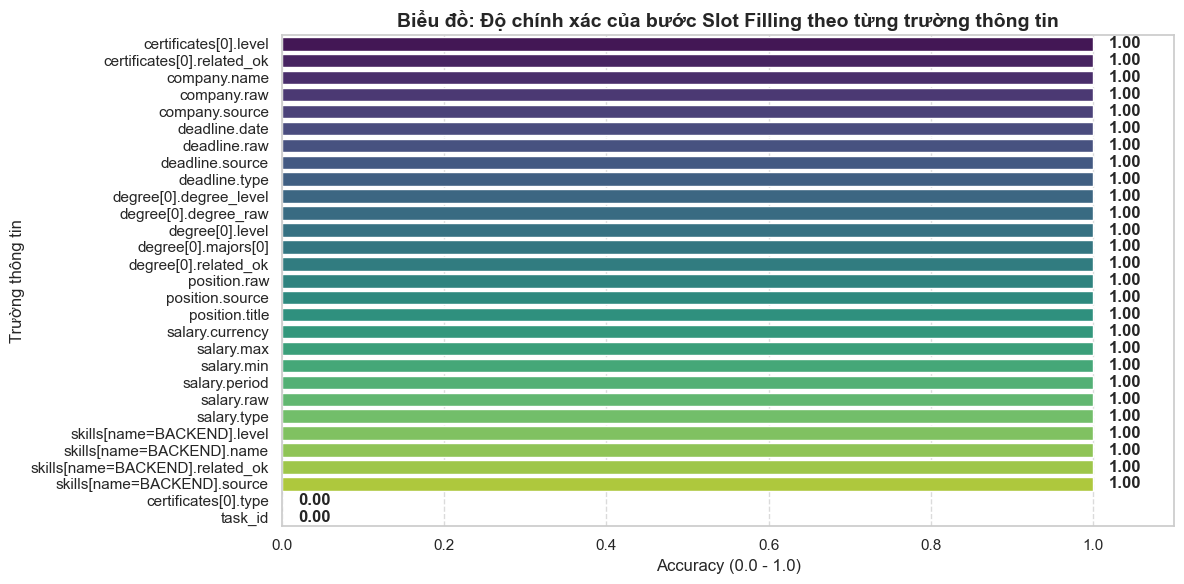

In [23]:
print("BẢNG 1: ĐÁNH GIÁ ĐỘ CHÍNH XÁC TRÊN TỪNG TASK")
task_results = []
for task, gold in TASKS:
    pred = filler.dien(task)
    r = sl.tinh_accuracy(gold, pred)
    task_results.append({
        "Task ID": task["task_id"],
        "Accuracy (%)": f"{r['accuracy']*100:.2f}%",
        "Số trường đúng / Tổng": f"{r['matched']} / {r['total']}",
        "Exact Match": "✅ Pass" if r["exact_match"] else "❌ Fail"
    })
df_tasks = pd.DataFrame(task_results)
display(df_tasks)

field_data = []
for path, stats in ds["field_accuracy"].items():
    if stats["total"] >= 3:
        field_data.append({
            "Field": path.replace("skill_groups", "skills").replace("locations", "locs"), # Rút gọn tên
            "Accuracy": stats["accuracy"]
        })

df_fields = pd.DataFrame(field_data).sort_values(by="Accuracy", ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=df_fields, x="Accuracy", y="Field", palette="viridis")
plt.title("Biểu đồ: Độ chính xác của bước Slot Filling theo từng trường thông tin", fontsize=14, fontweight="bold")
plt.xlabel("Accuracy (0.0 - 1.0)")
plt.ylabel("Trường thông tin")
plt.xlim(0, 1.1)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Thêm số liệu vào cuối mỗi cột
for i, v in enumerate(df_fields["Accuracy"]):
    plt.text(v + 0.02, i, f"{v:.2f}", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

### Phân tích thực thể có nhiều cách viết

Tổng số task sau khi gộp: 696


,Nhãn,Tổng số lần xuất hiện,Số Surface Forms (SF),Số Canonical Forms (CF),Độ đa dạng (SF/CF),Tỉ lệ Long-tail
0,Salary,19,13,8,1.62,53.8%
1,Experience,71,37,30,1.23,37.8%
2,Location,35,21,18,1.17,33.3%
3,Skill,670,300,281,1.07,36.7%
4,Certificate,10,5,5,1.00,0.0%
5,Degree,19,6,11,0.55,16.7%


Đã lưu biểu đồ tại: diversity_chart.png


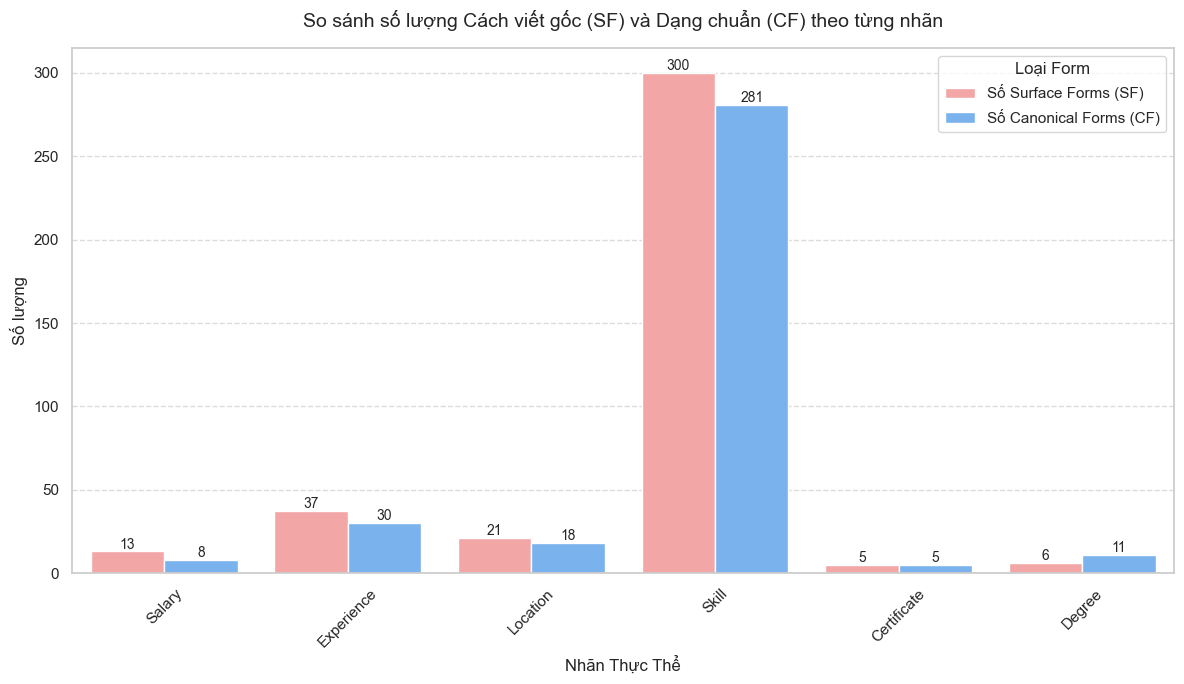

In [24]:

test_tasks1 = tu.load_json(r"..\..\Data\Dữ liệu Huấn Luyện\Train_Test_Dev_Anno1.json")
test_tasks2 = tu.load_json(r"..\..\Data\Dữ liệu Huấn Luyện\Train_Test_Dev_Anno3.json")
test_tasks3 = tu.load_json(r"..\..\Data\Dữ liệu Huấn Luyện\Train_Test_Dev_Anno4.json")

test_tasks = test_tasks1 + test_tasks2 + test_tasks3

print(f"Tổng số task sau khi gộp: {len(test_tasks)}")


for task in test_tasks:
    if task.get("split") == "test":
        pl.tao_text_chuan_hoa_2(task)       
        pl.tokenized_cho_tasks([task])        
        pl.bien_span_thanh_bio_cho_tasks([task]) 

X_test, _ = tu.lay_dong(test_tasks, split="test")
Y_pred = crf_test.predict(X_test)


filler = sl.SlotFiller()
analyzer = ed.DiversityAnalyzer(filler)


pred_idx = 0
for task in test_tasks:
    if task.get("split") != "test":
        continue
        
    bio_pred_task = []
    for _ in task["tokenized"]:
        bio_pred_task.append(Y_pred[pred_idx])
        pred_idx += 1
        
    task["bio"] = bio_pred_task
    bu.bien_bio_thanh_span(task) 
    analyzer.process_task(task)

df_metrics = analyzer.get_metrics()
display(df_metrics)
ed.plot_diversity_chart(df_metrics)

## Phân Tích Bắt Buộc

### Dữ liệu chứa emoji và ký tự đặc biệt

nhãn                 P       R      F1   số thật
BENEFIT          0.800   0.750   0.774        32
CERTIFICATE      0.500   0.500   0.500         8
COMPANY          0.714   0.357   0.476        14
DEADLINE         1.000   0.923   0.960        13
DEGREE           0.000   0.000   0.000        16
EXPERIENCE       0.700   0.778   0.737         9
LOCATION         1.000   0.923   0.960        26
POSITION         0.538   0.538   0.538        13
SALARY           0.556   0.227   0.323        22
SKILL            0.852   1.000   0.920        23
SKILL_GROUP      0.333   0.100   0.154        10
------------------------------------------------
micro            0.737   0.602   0.663       186
macro F1                         0.577


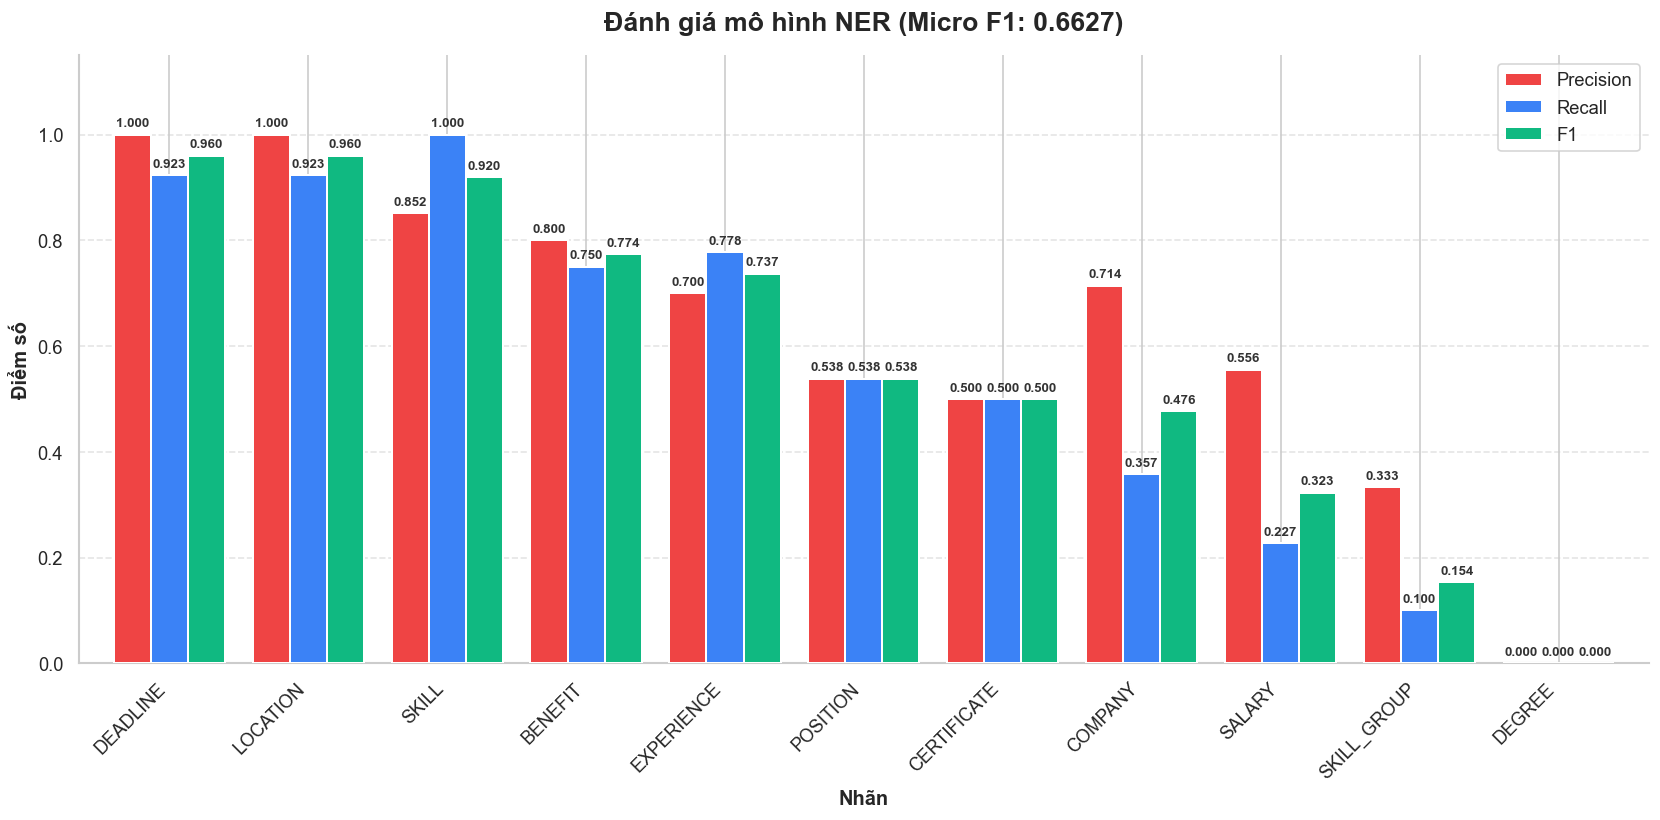

In [25]:
Y_pred_CRF_pt1 = crf_test.predict(X_test_pt1)
kq_crf_pt1 = bu.danh_gia(Y_test_pt1,Y_pred_CRF_pt1)
bu.in_ket_qua(kq_crf_pt1)
ve_bieu_do(kq_crf_pt1)

### Dữ liệu teencode và sai chính tả

nhãn                 P       R      F1   số thật
BENEFIT          0.500   0.529   0.514        51
CERTIFICATE      0.833   0.625   0.714         8
COMPANY          0.000   0.000   0.000        16
DEADLINE         1.000   0.312   0.476        16
DEGREE           0.400   0.500   0.444         4
EXPERIENCE       1.000   0.200   0.333        15
LOCATION         1.000   0.261   0.414        23
POSITION         0.929   0.722   0.813        18
SALARY           1.000   0.200   0.333        25
SKILL            0.672   0.907   0.772        43
SKILL_GROUP      0.500   0.333   0.400        15
------------------------------------------------
micro            0.663   0.470   0.550       234
macro F1                         0.474


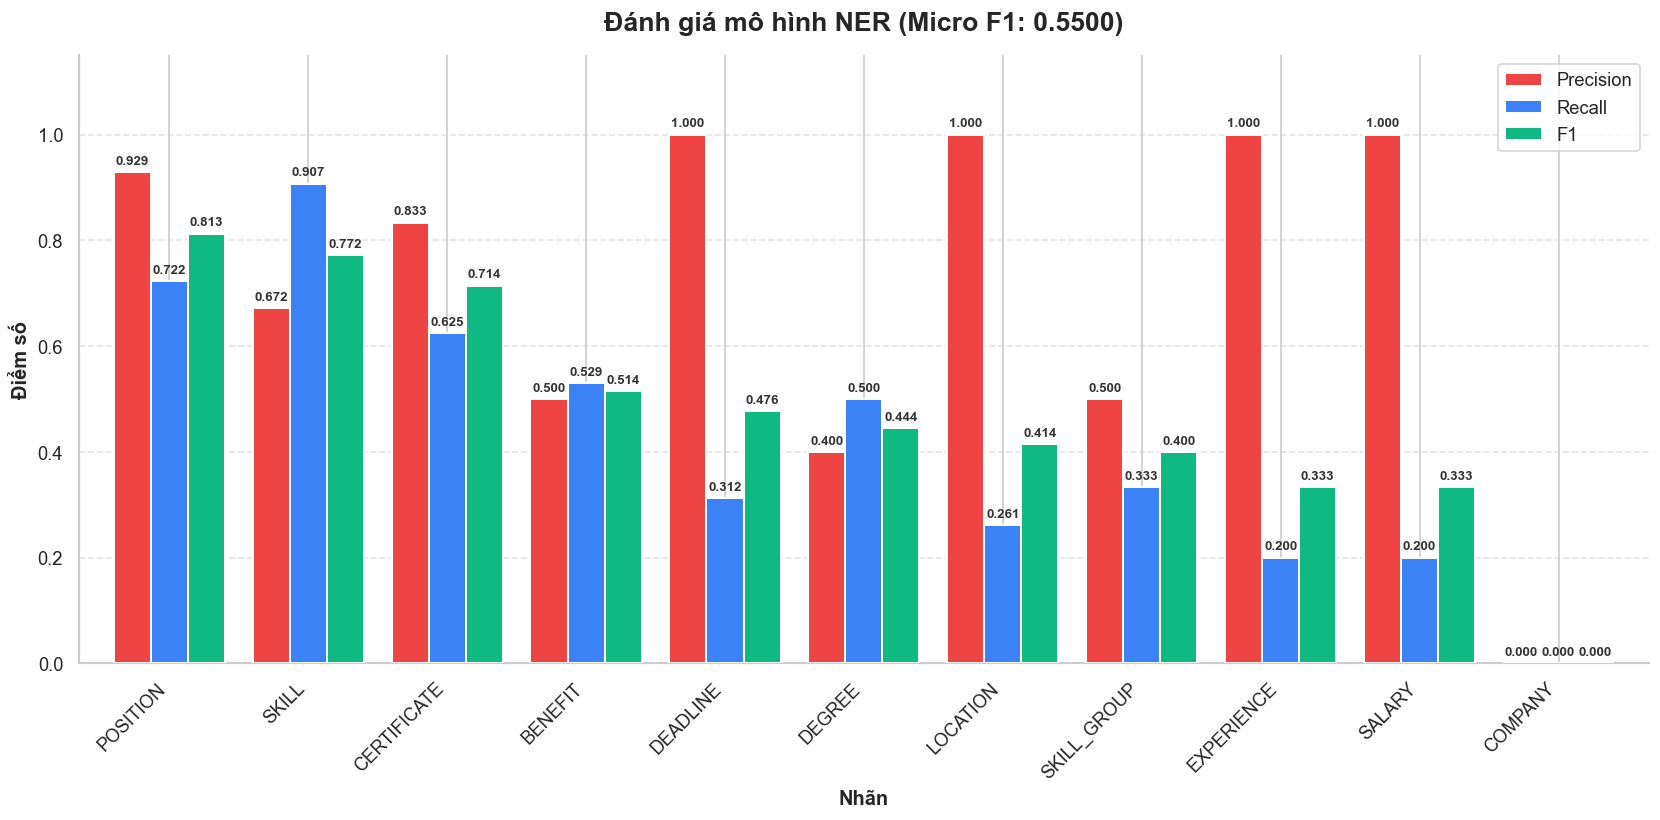

In [26]:
Y_pred_CRF_pt2 = crf_test.predict(X_test_pt2)
kq_crf_pt2 = bu.danh_gia(Y_test_pt2,Y_pred_CRF_pt2)
bu.in_ket_qua(kq_crf_pt2)
ve_bieu_do(kq_crf_pt2)